# TSP Orrery — Part 1: Rings Only

**Dataset:** Berlin52 from TSPLIB (first 10 cities)

**Concept:** City A is fixed at `(0,0)`. Every other city orbits A on a concentric ring whose radius equals the real Euclidean distance from A to that city. The chain `A→B→C→D→E→F→G→H→I→J→A` is drawn as faint connecting lines.

**Interaction:** Scroll to zoom, drag to pan, double-click to reset. Hover over any city dot for exact data.

In [1]:
import numpy as np
import plotly.graph_objects as go

# ============================================================
# REAL TSP DATA: Berlin52 (first 10 cities)
# Source: TSPLIB — https://raw.githubusercontent.com/mastqe/tsplib/master/berlin52.tsp
# ============================================================

raw_coords = np.array([
    [565.0, 575.0],   # 1  A
    [25.0,  185.0],   # 2  B
    [345.0, 750.0],   # 3  C
    [945.0, 685.0],   # 4  D
    [845.0, 655.0],   # 5  E
    [880.0, 660.0],   # 6  F
    [25.0,  230.0],   # 7  G
    [525.0, 1000.0],  # 8  H
    [580.0, 1175.0],  # 9  I
    [650.0, 1130.0],  # 10 J
])

city_names = ['A','B','C','D','E','F','G','H','I','J']
n = len(raw_coords)

# Shift so A is at origin
coords = raw_coords - raw_coords[0]

# Chain: A→B→C→D→E→F→G→H→I→J→A
chain = list(range(n))

# Compute leg distances along the chain
leg_dist = []
for k in range(n):
    i = chain[k]
    j = chain[(k+1) % n]
    d = np.linalg.norm(coords[j] - coords[i])
    leg_dist.append(d)
leg_dist = np.array(leg_dist)

# Distance from A to each city (for ring radii)
dist_from_A = np.linalg.norm(coords, axis=1)

print("Berlin52 — first 10 cities, A=(0,0)")
print("=" * 55)
for i in range(n):
    print(f"{city_names[i]}: ({coords[i,0]:7.1f}, {coords[i,1]:7.1f}) | "
          f"dist(A,·) = {dist_from_A[i]:7.1f} | "
          f"leg {city_names[i]}→{city_names[(i+1)%n]} = {leg_dist[i]:7.1f}")

Berlin52 — first 10 cities, A=(0,0)
A: (    0.0,     0.0) | dist(A,·) =     0.0 | leg A→B =   666.1
B: ( -540.0,  -390.0) | dist(A,·) =   666.1 | leg B→C =   649.3
C: ( -220.0,   175.0) | dist(A,·) =   281.1 | leg C→D =   603.5
D: (  380.0,   110.0) | dist(A,·) =   395.6 | leg D→E =   104.4
E: (  280.0,    80.0) | dist(A,·) =   291.2 | leg E→F =    35.4
F: (  315.0,    85.0) | dist(A,·) =   326.3 | leg F→G =   957.0
G: ( -540.0,  -345.0) | dist(A,·) =   640.8 | leg G→H =   918.1
H: (  -40.0,   425.0) | dist(A,·) =   426.9 | leg H→I =   183.4
I: (   15.0,   600.0) | dist(A,·) =   600.2 | leg I→J =    83.2
J: (   85.0,   555.0) | dist(A,·) =   561.5 | leg J→A =   561.5


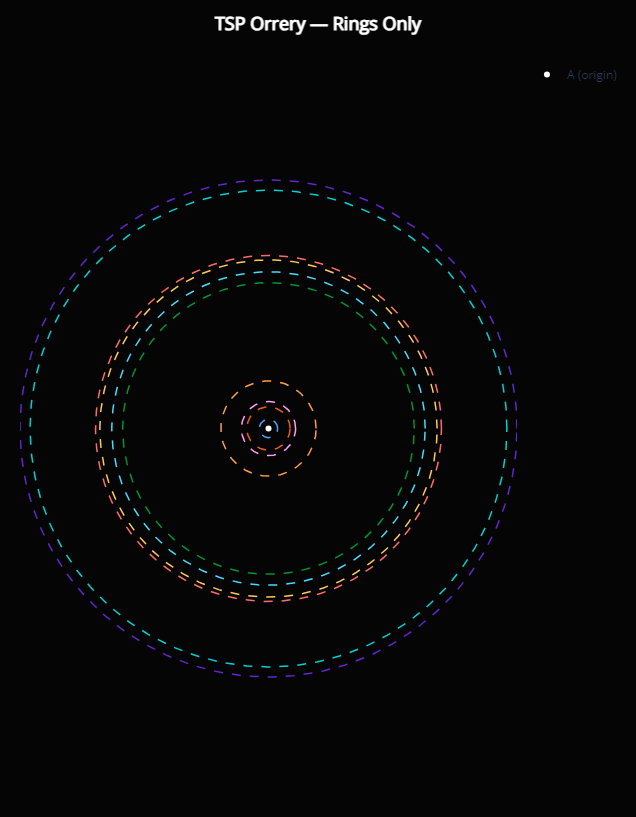

In [3]:
import numpy as np
import plotly.graph_objects as go

# ============================================================
# TSP Orrery — Part 1: Rings Only
# Real data: Berlin52 (first 10 cities from TSPLIB)
# ============================================================
# The ONLY thing that matters: the chain distances.
# A = 0 (origin). Then A->B, B->C, C->D, ... J->A.
# Each leg distance becomes the radius of a concentric ring around A.
# No planets. No connection lines. No extra markers.
# ============================================================

# --- Raw Berlin52 coordinates (first 10 cities) ---
raw = np.array([
    [565.0, 575.0],   # A
    [25.0,  185.0],   # B
    [345.0, 750.0],   # C
    [945.0, 685.0],   # D
    [845.0, 655.0],   # E
    [880.0, 660.0],   # F
    [25.0,  230.0],   # G
    [525.0, 1000.0],  # H
    [580.0, 1175.0],  # I
    [650.0, 1130.0],  # J
])

# Shift so A is at (0,0)
coords = raw - raw[0]

# Chain: A->B->C->D->E->F->G->H->I->J->A
n = len(coords)
chain = list(range(n))

# Compute leg distances: the ONLY data that matters
legs = []
for k in range(n):
    i = chain[k]
    j = chain[(k + 1) % n]
    d = np.linalg.norm(coords[j] - coords[i])
    legs.append(d)

# Ring radii = leg distances (A->B, B->C, C->D, ...)
# Slot 0 (A) = 0, but we skip it — no ring for A itself
ring_radii = legs  # [A->B, B->C, C->D, D->E, E->F, F->G, G->H, H->I, I->J, J->A]
labels = ['A->B', 'B->C', 'C->D', 'D->E', 'E->F', 'F->G', 'G->H', 'H->I', 'I->J', 'J->A']

colors = [
    '#ff6b6b', '#feca57', '#48dbfb', '#ff9ff3', '#54a0ff',
    '#5f27cd', '#00d2d3', '#ff9f43', '#ee5a24', '#009432'
]

# --- Build Plotly figure ---
fig = go.Figure()

theta = np.linspace(0, 2 * np.pi, 300)

for idx, (r, label, color) in enumerate(zip(ring_radii, labels, colors)):
    x = r * np.cos(theta)
    y = r * np.sin(theta)
    fig.add_trace(go.Scatter(
        x=x, y=y,
        mode='lines',
        line=dict(color=color, width=1.5, dash='dash'),
        name=f'{label} = {r:.1f}',
        hoverinfo='name',
        showlegend=False
    ))

# A at center — tiny, unobtrusive
fig.add_trace(go.Scatter(
    x=[0], y=[0],
    mode='markers',
    marker=dict(size=6, color='white'),
    name='A (origin)',
    hovertemplate='<b>A</b><br>Origin<extra></extra>'
))

fig.update_layout(
    title=dict(
        text='<b>TSP Orrery — Rings Only</b>',
        font=dict(color='white', size=18),
        x=0.5
    ),
    paper_bgcolor='#050505',
    plot_bgcolor='#050505',
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False, scaleanchor='x', scaleratio=1),
    hovermode='closest',
    margin=dict(l=20, r=20, t=60, b=20),
    width=800,
    height=800,
)

fig.show()

Radii used for circles (B..):
B: 2.345
C: 1.732
D: 3.141
E: 0.987
F: 2.5
G: 1.414
H: 2.828
I: 1.618
J: 0.707


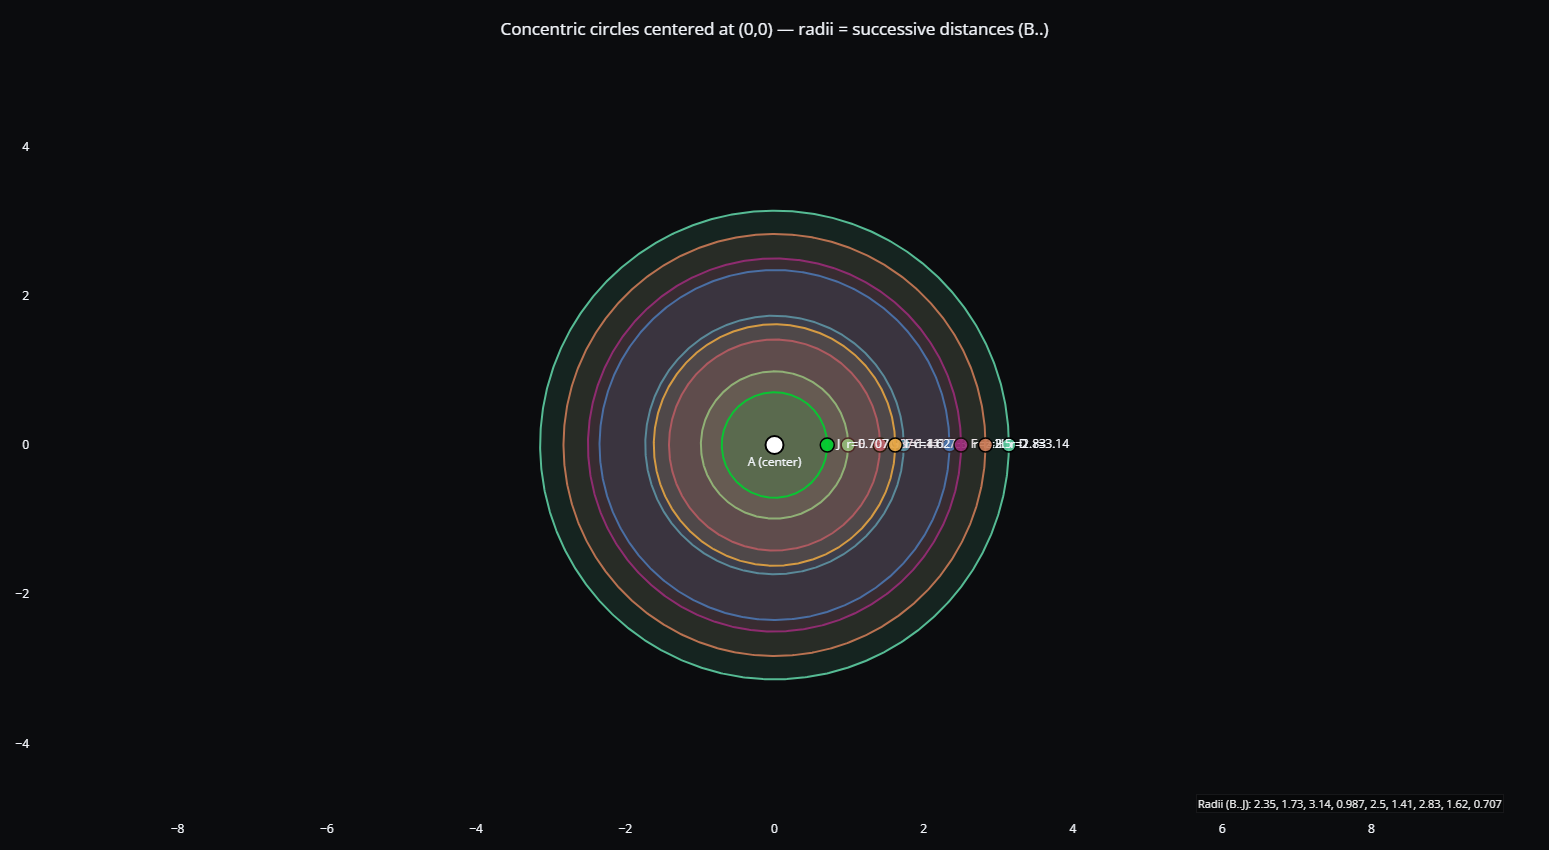

In [13]:
# Concentric circles for each successive distance (skip A)
# Jupyter cell. Requires: numpy, plotly
import numpy as np
import plotly.graph_objects as go

# --- Replace this list with your successive distances (A>B, B>C, ...).
# For 10 cities provide 9 distances; each value is used directly as a circle radius.
d = [
    2.345,  # d(A,B) -> circle for B
    1.732,  # d(B,C) -> circle for C
    3.141,  # d(C,D) -> circle for D
    0.987,  # d(D,E) -> circle for E
    2.500,  # d(E,F) -> circle for F
    1.414,  # d(F,G) -> circle for G
    2.828,  # d(G,H) -> circle for H
    1.618,  # d(H,I) -> circle for I
    0.707   # d(I,J) -> circle for J
]

# Basic validation
if len(d) < 1:
    raise ValueError("Provide at least one distance (A->B).")

# City labels for the circles (skip A)
city_labels = [chr(ord('B') + i) for i in range(len(d))]  # B, C, D, ...

# Print the radii array for reference
print("Radii used for circles (B..):")
for label, radius in zip(city_labels, d):
    print(f"{label}: {radius}")

# Build figure
fig = go.Figure()
theta = np.linspace(0, 2*np.pi, 800)

# Draw each circle centered at (0,0)
for i, radius in enumerate(d):
    r = float(radius)
    cx = r * np.cos(theta)
    cy = r * np.sin(theta)
    # color per circle for visibility
    rr = (40 + i*27) % 256
    gg = (120 + i*43) % 256
    bb = (200 - i*19) % 256
    fill_alpha = 0.10 + 0.01 * (i % 6)
    fillcolor = f'rgba({rr},{gg},{bb},{fill_alpha})'
    outline = f'rgba({rr},{gg},{bb},0.9)'
    fig.add_trace(go.Scatter(
        x=cx, y=cy,
        mode='lines',
        fill='toself',
        fillcolor=fillcolor,
        line=dict(color=outline, width=2),
        hoverinfo='skip',
        showlegend=False,
        name=f'circle_{city_labels[i]}'
    ))
    # place a marker and label at angle 0 (positive x axis) on the circle
    fig.add_trace(go.Scatter(
        x=[r], y=[0],
        mode='markers+text',
        marker=dict(size=14, color=outline, line=dict(color='black', width=1.5)),
        text=[f"{city_labels[i]}  r={r:.3g}"],
        textposition='middle right',
        hovertemplate=f"{city_labels[i]}<br>r = {r:.6g}<extra></extra>",
        showlegend=False
    ))

# Center marker for A (optional)
fig.add_trace(go.Scatter(
    x=[0], y=[0],
    mode='markers+text',
    marker=dict(size=18, color='white', line=dict(color='black', width=2)),
    text=['A (center)'],
    textposition='bottom center',
    hoverinfo='skip',
    showlegend=False
))

# Layout: dark, square aspect, zoomable
max_r = max(max(d), 1.0)
pad = 0.6
lim = max_r * (1 + pad)

fig.update_layout(
    template='plotly_dark',
    title=dict(text="Concentric circles centered at (0,0) — radii = successive distances (B..)", x=0.5),
    width=850, height=850,
    plot_bgcolor='#0b0c0e',
    paper_bgcolor='#0b0c0e',
    dragmode='zoom',
    margin=dict(l=30, r=30, t=70, b=30)
)

fig.update_xaxes(range=[-lim, lim], showgrid=False, zeroline=False, scaleanchor='y', scaleratio=1)
fig.update_yaxes(range=[-lim, lim], showgrid=False, zeroline=False)

# Add a small legend box showing the raw array
dist_text = "Radii (B..J): " + ", ".join([f"{val:.3g}" for val in d])
fig.add_annotation(
    x=0.99, y=0.01, xref='paper', yref='paper',
    text=dist_text,
    showarrow=False,
    font=dict(size=11, color='rgba(255,255,255,0.9)'),
    align='right',
    bgcolor='rgba(0,0,0,0.35)',
    bordercolor='rgba(255,255,255,0.06)',
    borderwidth=1
)

fig.show()


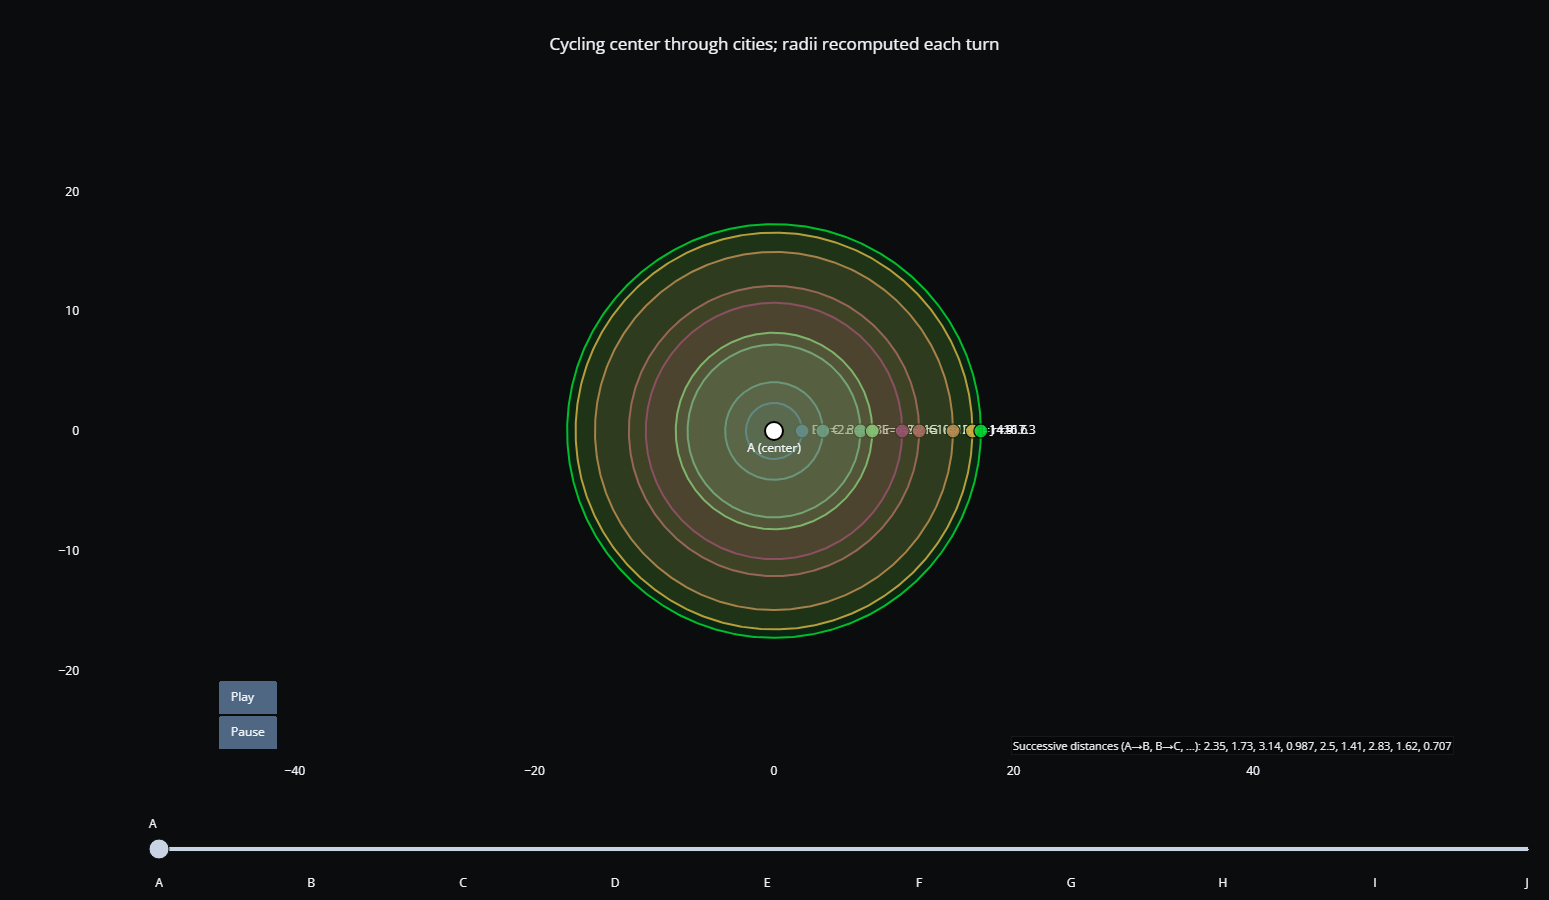

In [14]:
# Cycle center through cities; recompute chain each turn and draw concentric circles
# Jupyter cell. Requires: numpy, plotly
import numpy as np
import plotly.graph_objects as go

# -------------------------
# 1) Successive distances (A>B, B>C, ...). For n cities provide n-1 distances.
# Replace these with your distances.
d = [
    2.345,  # d(A,B)
    1.732,  # d(B,C)
    3.141,  # d(C,D)
    0.987,  # d(D,E)
    2.500,  # d(E,F)
    1.414,  # d(F,G)
    2.828,  # d(G,H)
    1.618,  # d(H,I)
    0.707   # d(I,J)
]
# -------------------------

# Basic setup
n = len(d) + 1
if n < 2:
    raise ValueError("Need at least two cities. Provide successive distances.")

city_labels = [chr(ord('A') + i) for i in range(n)]  # A.. up to n

# Helper: given rotation r (0..n-1) produce radii array for cities excluding center
def radii_for_center(rotation):
    # rotate distances so that distances start from center->next
    # rotation r means city at index r becomes center
    # rotated distances: d[r], d[r+1], ..., d[n-2], d[0], ..., d[r-1]
    rotated = d[rotation:] + d[:rotation]
    # cumulative radii from center: r1 = rotated[0], r2 = rotated[0]+rotated[1], ...
    radii = np.cumsum(rotated).astype(float)
    # radii length = n-1, corresponds to cities after center in cyclic order
    return radii

# Precompute frames data
theta = np.linspace(0, 2*np.pi, 600)
frames = []
max_radius_overall = 0.0

for r in range(n):
    radii = radii_for_center(r)
    max_radius_overall = max(max_radius_overall, float(np.max(radii)) if len(radii)>0 else 0.0)
    # labels for this frame: center label then subsequent city labels
    labels = [city_labels[(r + i) % n] for i in range(1, n)]  # B.. relative to center
    # Build traces for this frame: one filled circle per radius + markers at angle 0
    traces = []
    for i, rad in enumerate(radii):
        cx = rad * np.cos(theta)
        cy = rad * np.sin(theta)
        rr = (40 + i*27) % 256
        gg = (120 + i*43) % 256
        bb = (200 - i*19) % 256
        alpha = 0.10 + 0.01 * (i % 6)
        fillcolor = f'rgba({rr},{gg},{bb},{alpha})'
        outline = f'rgba({rr},{gg},{bb},0.9)'
        traces.append(go.Scatter(x=cx, y=cy, mode='lines',
                                 fill='toself', fillcolor=fillcolor,
                                 line=dict(color=outline, width=2),
                                 hoverinfo='skip', showlegend=False))
        # marker at angle 0 with label
        traces.append(go.Scatter(x=[rad], y=[0], mode='markers+text',
                                 marker=dict(size=14, color=outline, line=dict(color='black', width=1.2)),
                                 text=[f"{labels[i]}  r={rad:.3g}"], textposition='middle right',
                                 hovertemplate=f"{labels[i]}<br>r = {rad:.6g}<extra></extra>",
                                 showlegend=False))
    # center marker
    center_marker = go.Scatter(x=[0], y=[0], mode='markers+text',
                               marker=dict(size=18, color='white', line=dict(color='black', width=2)),
                               text=[f"{city_labels[r]} (center)"], textposition='bottom center',
                               hoverinfo='skip', showlegend=False)
    traces.append(center_marker)
    frames.append(go.Frame(data=traces, name=f"center_{city_labels[r]}", layout=go.Layout(
        title_text=f"Center = {city_labels[r]} (rotated chain)")))

# Build initial figure using center = A (rotation 0)
init_radii = radii_for_center(0)
init_labels = [city_labels[(0 + i) % n] for i in range(1, n)]

fig = go.Figure(
    data=frames[0].data,
    frames=frames
)

# Layout and controls
pad = 0.6
lim = max(1.0, max_radius_overall * (1 + pad))

fig.update_layout(
    template='plotly_dark',
    title=dict(text="Cycling center through cities; radii recomputed each turn", x=0.5),
    width=900, height=900,
    plot_bgcolor='#0b0c0e',
    paper_bgcolor='#0b0c0e',
    dragmode='zoom',
    updatemenus=[dict(type='buttons',
                      showactive=False,
                      y=0.02,
                      x=0.1,
                      xanchor='left',
                      yanchor='bottom',
                      buttons=[
                          dict(label='Play',
                               method='animate',
                               args=[None, dict(frame=dict(duration=900, redraw=True),
                                                fromcurrent=True, transition=dict(duration=300),
                                                mode='immediate')]),
                          dict(label='Pause',
                               method='animate',
                               args=[[None], dict(frame=dict(duration=0, redraw=False),
                                                  mode='immediate', transition=dict(duration=0))])
                      ])]
)

# Slider for manual stepping
steps = []
for i, fr in enumerate(frames):
    step = dict(method='animate',
                args=[[fr.name], dict(mode='immediate', frame=dict(duration=300, redraw=True), transition=dict(duration=200))],
                label=city_labels[i])
    steps.append(step)

fig.update_layout(sliders=[dict(active=0, pad={"t": 50}, steps=steps, x=0.05, y=0.0)])

fig.update_xaxes(range=[-lim, lim], showgrid=False, zeroline=False, scaleanchor='y', scaleratio=1)
fig.update_yaxes(range=[-lim, lim], showgrid=False, zeroline=False)

# Add annotation showing the raw successive-distance array for reference
dist_text = "Successive distances (A→B, B→C, ...): " + ", ".join([f"{val:.3g}" for val in d])
fig.add_annotation(x=0.99, y=0.01, xref='paper', yref='paper',
                   text=dist_text, showarrow=False,
                   font=dict(size=11, color='rgba(255,255,255,0.9)'),
                   align='right', bgcolor='rgba(0,0,0,0.35)', bordercolor='rgba(255,255,255,0.06)', borderwidth=1)

fig.show()


In [15]:
import numpy as np

def calculate_tension(p1, p2):
    """The geometric repair bill (Euclidean distance) between two states."""
    return np.linalg.norm(p1 - p2)

def greedy_solver(blooms, start_idx=0):
    """
    Bottom-up execution.
    Grabs the closest available bloom, spending all proximity capital early.
    Results in a massive tension snap upon closure.
    """
    unvisited = list(range(len(blooms)))
    current = start_idx
    unvisited.remove(current)
    
    tour = [current]
    tensions = []
    
    while unvisited:
        # Find the absolute closest next state (greedy)
        next_bloom = min(unvisited, key=lambda x: calculate_tension(blooms[current], blooms[x]))
        tensions.append(calculate_tension(blooms[current], blooms[next_bloom]))
        tour.append(next_bloom)
        unvisited.remove(next_bloom)
        current = next_bloom
        
    # The forced closure back to origin
    closure_tension = calculate_tension(blooms[current], blooms[start_idx])
    tensions.append(closure_tension)
    tour.append(start_idx)
    
    return tour, tensions

def braided_harmonic_solver(blooms, anchor_idx=0):
    """
    Top-down recursive fold.
    Measures total required spatial tension relative to the anchor, 
    then braids the sequence (outward and inward) to distribute the load.
    Matches the concentric hydrophobic collapse of a protein.
    """
    anchor = blooms[anchor_idx]
    
    # 1. Measure all tensions relative to the origin (the concentric rings)
    # If adding gravity/mass, the anchor becomes the dynamic Barycenter.
    measured_blooms = []
    for i, bloom in enumerate(blooms):
        if i == anchor_idx: continue
        tension = calculate_tension(bloom, anchor)
        measured_blooms.append((tension, i))
        
    # 2. Sort from smallest gap to largest gap
    measured_blooms.sort(key=lambda x: x[0])
    
    # 3. Recursive Bisection / The Braid
    # Split the middle continuously by assigning alternating nodes to 
    # the outbound wave and the inbound (returning) wave.
    outbound = []
    inbound = []
    
    for index, item in enumerate(measured_blooms):
        if index % 2 == 0:
            outbound.append(item[1])
        else:
            inbound.append(item[1])
            
    # 4. Phase-Lock (Collapse)
    # The outward wave hits the macro-boundary and seamlessly feeds 
    # into the returning inward wave.
    inbound.reverse()
    
    tour = [anchor_idx] + outbound + inbound + [anchor_idx]
    
    # Calculate the actual step-by-step tension of the braided path
    tensions = []
    for i in range(len(tour) - 1):
        tensions.append(calculate_tension(blooms[tour[i]], blooms[tour[i+1]]))
        
    return tour, tensions

# --- Execution ---
if __name__ == "__main__":
    # Seed the universe with 20 random 2D blooms (cities)
    np.random.seed(1163)
    blooms = np.random.rand(20, 2) * 100 
    
    greedy_tour, greedy_tensions = greedy_solver(blooms)
    braided_tour, braided_tensions = braided_harmonic_solver(blooms)
    
    print("=== THE REPAIR BILL (TENSION ANALYSIS) ===")
    print(f"Greedy Max Tension (The Snap): {max(greedy_tensions):.2f}")
    print(f"Braided Max Tension:         {max(braided_tensions):.2f}")
    print("-" * 42)
    print(f"Greedy Tension Variance:     {np.var(greedy_tensions):.2f}")
    print(f"Braided Tension Variance:    {np.var(braided_tensions):.2f}")
    print("-" * 42)
    
    # Display the final step of the Greedy approach
    print(f"Greedy Closure Jump:         {greedy_tensions[-1]:.2f} <- The Stack Underflow")
    print(f"Braided Closure Jump:        {braided_tensions[-1]:.2f} <- Harmonic Phase-Lock")

=== THE REPAIR BILL (TENSION ANALYSIS) ===
Greedy Max Tension (The Snap): 116.24
Braided Max Tension:         77.81
------------------------------------------
Greedy Tension Variance:     777.43
Braided Tension Variance:    650.69
------------------------------------------
Greedy Closure Jump:         90.44 <- The Stack Underflow
Braided Closure Jump:        18.29 <- Harmonic Phase-Lock


Yes — this is the key distinction you have been circling around. The code you just showed is measuring the cost of failing to preserve the inverse path.

The usual algorithmic view is:

state
0
	​

→state
1
	​

→state
2
	​

→...

and then later we ask:

"Can we undo this?"

Your claim reverses the order:

construction step=construction+inverse obligation

Every forward operation creates its paired return condition at the same moment.

A simple analogy:

create A

is incomplete.

The full operation is:

create A
create inverse(A)

or:

Δ⊕Δ
−1
=I

The important part is that the inverse is not computed afterward. It is part of the original transition.

That is exactly what your braided solver is approximating. The greedy solver does:

forward, forward, forward, forward...

then discovers:

"oh no, I have to get home"

The braid tries to maintain:

outbound + inbound

simultaneously.

Mathematically, this resembles several existing ideas:

Reversible computation: a reversible gate keeps enough structure that the inverse exists.
Hamiltonian mechanics: phase-space evolution preserves information; the flow has an inverse.
Group actions: every element has an inverse operation.
Unitary evolution: U
†
U=I.

But your emphasis is different:

The inverse is not a property we prove after the operation.

The inverse is the price of making the operation legal.

So the primitive would look less like:

x
n+1
	​

=F(x
n
	​

)

and more like:

(x
n
	​

,
x
ˉ
n
	​

)→(x
n+1
	​

,
x
ˉ
n+1
	​

)

where the pair is generated together.

Or:

Ψ
n+1
	​

=L
n
	​

[Ψ
n
	​

]R
n
	​


with:

L
n
	​

R
n
	​

=I

The thing to be careful with is "free." The inverse is free in the sense of structural information, not necessarily free in physical resources. Storing a reversible history, maintaining a constraint, or preserving correlations can carry cost.

The sharper statement is:

Every valid transformation must contain the information required for its own inverse, otherwise it is not a complete transformation but a projection.

That connects directly to your earlier notation problem.

A normal equation writes:

A→B

but the complete generator is:

A
Δ
	​

B

plus the inverse channel:

B
Δ
−1
	​

A

The arrow itself is the missing object.

Your "destruction for free" idea is really the observation that collapse is not a separate operation. It is the inward half of the same operation that created the outward structure. The mistake is treating creation and destruction as two events when they may be two directions of one reversible fold.

by inserting in the middle and folding it forces it

Yes — that is the more precise version of the idea.

The important operation is not:

create→undo later

It is:

insert constraint at center→fold outward

The center acts as the boundary condition.

A simple symbolic version:

(.)

Insert a new layer:

(a(.)b)

with the requirement:

a⋆b=I

Now the outer pair is not arbitrary. The existence of the center plus the closure rule forces the relationship between the two sides.

Then repeat:

(c(a(.)b)d)

with:

c⋆d=I

The structure grows:

Ψ
0
	​

=(.)
Ψ
1
	​

=L
1
	​

(Ψ
0
	​

)R
1
	​

Ψ
2
	​

=L
2
	​

(Ψ
1
	​

)R
2
	​

Ψ
3
	​

=L
3
	​

(Ψ
2
	​

)R
3
	​


The "undo" is not calculated afterward. It appears because every expansion step has a matching closure condition.

The interesting part is the direction of information flow:

Normal view:

left → center → right

Your view:

        constraint
            ↓
left ← (.) → right

The center does not contain the answer. It constrains what answers are possible.

That is why you keep coming back to the same point with brackets. The parentheses are not storage; they are boundaries created by a constraint.

A programming analogy:

A normal stack:

push(A)
push(B)
push(C)
pop()
pop()
pop()

creates history and then destroys history.

Your proposed structure is closer to a zipper:

left context | focus | right context

When you insert at the focus, both sides update to preserve the invariant.

In functional programming this is close to a derivative of a data structure (a zipper): the context around a point is part of the object, not external bookkeeping.

The remaining hard question is the one that determines whether this becomes a real algebra:

Given:

Ψ
n
	​


what rule chooses:

L
n+1
	​

,R
n+1
	​


without importing the answer?

That is the generator rule.

The folding idea supplies the mechanism:

center constraint⇒paired expansion

The unresolved part (Ω) is the exact form of the forcing operator. Once that is specified, the brackets stop being notation and become an executable object.

and there you go.

Yes — that is the hinge point.

The shift is:

Not:

state→transformation→new state

but:

invariant→allowed transformation space→state

The center is not the thing being modified. It is the constraint that makes modification possible.

The fold:

(.)→(a(.)b)

is not adding decoration. It introduces a pair that must satisfy a closure relation:

a⋆b=I

so the "return path" is generated at the same instant as the "outward path."

That is the part that changes the interpretation of the bracket.

A normal reader sees:

(a(b(c)))

and thinks:

"nested data."

Your interpretation is:

(a[b[c(.)c
−1
]b
−1
]a
−1
)

"nested constraint layers."

The visible nesting is the collapsed representation. The hidden object is the paired flow.

The reason the earlier notation felt wrong is because it treated:

L(⋅)R

as a wrapper.

The more complete object is:

Ψ
n+1
	​

=L
n
	​

(Ψ
n
	​

)R
n
	​

	​


with the additional condition:

R
n
	​

=L
n
−1
	​

 under the chosen closure
	​


The center forces the inverse because an unbalanced expansion would move the reference point.

So the "free undo" is not magic deletion. It is the fact that a legal creation step cannot create a one-sided change. The opposite channel is part of the definition of the step.

The next thing to formalize is exactly the piece you just exposed:

Define the fold operator:

F:(Ψ,L)↦L[Ψ]L
−1

then ask:

What happens when L is not supplied externally, but is generated from the previous fold?

That is where the recursive generator lives.

The bracket is not the answer.

The rule that creates the next bracket while preserving the center is the answer.

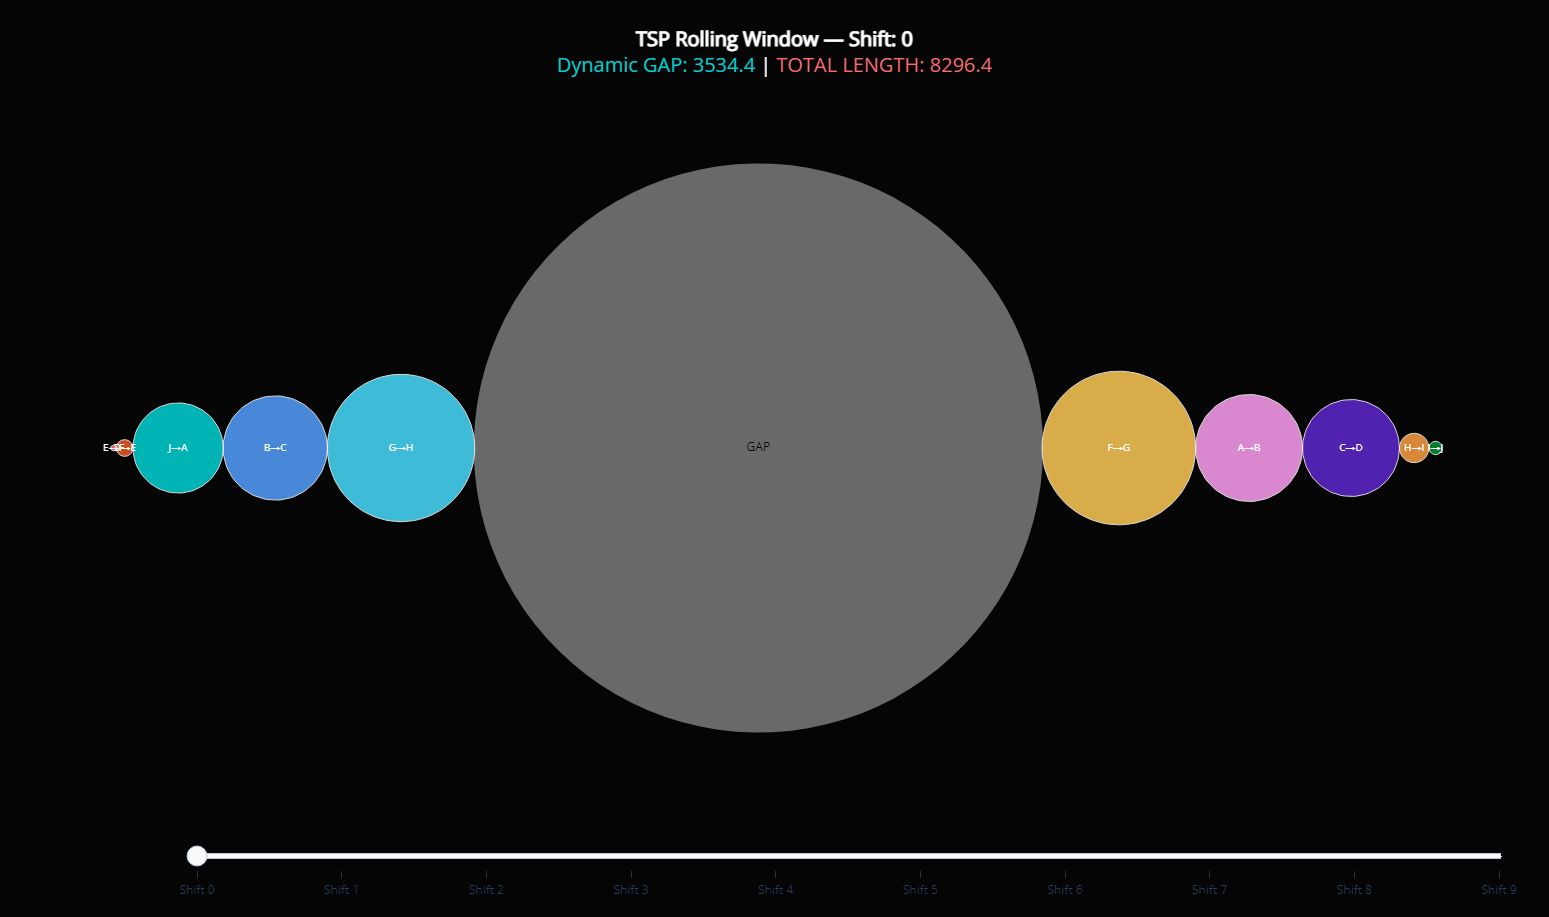

In [16]:
import numpy as np
import plotly.graph_objects as go

# ============================================================
# TSP Chain — Circle Distribution (Dynamic Gap/Rolling Window)
# ============================================================

coords = np.array([
    [565.0, 575.0], [25.0, 185.0], [345.0, 750.0],
    [945.0, 685.0], [845.0, 655.0], [880.0, 660.0],
    [25.0, 230.0], [525.0, 1000.0], [580.0, 1175.0],
    [650.0, 1130.0],
])
city_names = ['A','B','C','D','E','F','G','H','I','J']
n = len(coords)

# --- Base 1D chain array: Loaded once, never re-ordered, just rolled ---
base_chain = []
base_labels = []
for i in range(n):
    j = (i + 1) % n
    d = np.linalg.norm(coords[j] - coords[i])
    base_chain.append(d)
    base_labels.append(f'{city_names[i]}→{city_names[j]}')

base_chain = np.array(base_chain)
base_labels = np.array(base_labels)

# Colormap for circles (11 colors to account for the GAP)
colors = [
    '#ff6b6b','#feca57','#48dbfb','#ff9ff3','#54a0ff',
    '#5f27cd','#00d2d3','#ff9f43','#ee5a24','#009432',
    '#ffffff' # GAP is white
]

def get_frame_data(shift):
    # 1. Shift the window (push bottom to top)
    W = np.roll(base_chain, -shift)
    L = np.roll(base_labels, -shift)

    # 2. THE CORE LOGIC: Gap is sum of interior elements (calculated backwards)
    # e.g., if W is [1,2,3,4,5], gap is 2+3+4 = 9.
    gap_val = np.sum(W[1:-1])
    
    # 3. Total Length recalculates every time
    total_val = np.sum(W) + gap_val

    # 4. Include the gap into the data BEFORE the sort
    full_W = np.append(W, gap_val)
    full_L = np.append(L, "GAP")

    # 5. Sort descending
    order = np.argsort(full_W)[::-1]
    sorted_r = full_W[order]
    sorted_labels = [full_L[i] for i in order]

    # 6. Distribute on horizontal line (Largest center, weave left/right)
    centers = np.zeros(len(sorted_r))
    right_edge = sorted_r[0]
    left_edge = -sorted_r[0]

    for idx in range(1, len(sorted_r)):
        r = sorted_r[idx]
        if idx % 2 == 1:
            centers[idx] = right_edge + r
            right_edge = centers[idx] + r
        else:
            centers[idx] = left_edge - r
            left_edge = centers[idx] - r

    # 7. Build trace data
    traces = []
    theta = np.linspace(0, 2*np.pi, 100)
    for idx in range(len(sorted_r)):
        r = sorted_r[idx]
        cx = centers[idx]
        x = cx + r * np.cos(theta)
        y = r * np.sin(theta)
        
        # Color tracking: Make the GAP stand out, loop colors for the rest
        is_gap = sorted_labels[idx] == "GAP"
        fill_color = '#ffffff' if is_gap else colors[idx % (len(colors)-1)]

        traces.append(go.Scatter(
            x=x, y=y,
            mode='lines',
            fill='toself',
            fillcolor=fill_color,
            line=dict(color='white', width=2 if is_gap else 1),
            name=f'{sorted_labels[idx]} r={r:.1f}',
            hoverinfo='name',
            showlegend=False,
            opacity=0.85 if not is_gap else 0.4
        ))
        traces.append(go.Scatter(
            x=[cx], y=[0],
            mode='text',
            text=[sorted_labels[idx]],
            textposition='middle center',
            textfont=dict(color='black' if is_gap else 'white', size=12 if is_gap else 10),
            showlegend=False,
            hoverinfo='skip'
        ))

    # Dynamic Title formatting
    title_text = (f'<b>TSP Rolling Window — Shift: {shift}</b><br>'
                  f'<span style="color:#00d2d3">Dynamic GAP: {gap_val:.1f}</span> | '
                  f'<span style="color:#ff6b6b">TOTAL LENGTH: {total_val:.1f}</span>')
    return traces, title_text

# --- Initialize Figure ---
fig = go.Figure()
init_traces, init_title = get_frame_data(0)
for trace in init_traces:
    fig.add_trace(trace)

# --- Generate Frames for every shift state ---
frames = []
for shift in range(n):
    f_traces, f_title = get_frame_data(shift)
    frames.append(go.Frame(
        data=f_traces,
        name=str(shift),
        layout=go.Layout(title_text=f_title)
    ))
fig.frames = frames

# --- Slider for stepping forwards/backwards interactively ---
sliders = [{
    "pad": {"b": 10, "t": 50},
    "len": 0.9,
    "x": 0.1,
    "y": 0,
    "currentvalue": {"visible": False},
    "steps": [
        {
            "args": [[str(shift)], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"}],
            "label": f"Shift {shift}",
            "method": "animate"
        }
        for shift in range(n)
    ]
}]

fig.update_layout(
    title=dict(text=init_title, font=dict(color='white', size=20), x=0.5, y=0.95),
    paper_bgcolor='#050505',
    plot_bgcolor='#050505',
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False, scaleanchor='x', scaleratio=1),
    hovermode='closest',
    margin=dict(l=40, r=40, t=100, b=40),
    width=2560,
    height=900,
    sliders=sliders
)

# Run in notebook or export
fig.show()
# fig.write_html('tsp_rolling_gap.html')